Laboratorio 8, Fisica Computacional

Juan Manuel Patiño

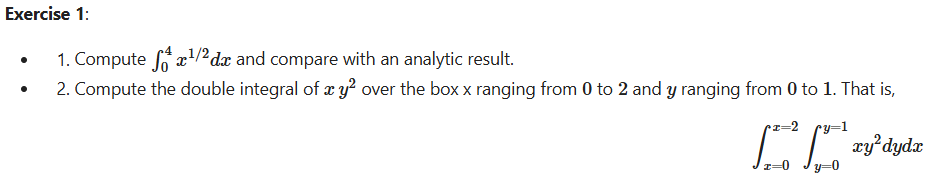

In [2]:
#librerias
import numpy as np
import random
import matplotlib.pyplot as plt
import scipy.integrate as integrate

In [3]:
def MC(f,a,b,N=10000):
  np.random.seed(42)
  """
  Calcula la integral definida usando el método del Valor Medio de Monte Carlo.
  Parámetros:
  f: La función
  a: Límite inferior
  b: Límite superior
  N: Número de muestras aleatorias
  """

  Nnums = np.random.uniform(a, b, N) #generamos una lista de N numeros
  media = (sum(f(Nnums))/N)*(b-a)

  return media

In [4]:
#Ejercicio 1 parte 1
F = lambda x: x**(1/2)
I = integrate.quad(F, 0, 4)
MC1 = MC(F,0,4,10000)

print(f"Monte carlo: {MC1}")
print(f"SciPy: {I[0]}")
print()
print(f"Error: {abs(I[0]-MC1)}")

Monte carlo: 5.299036695529751
SciPy: 5.333333333333335

Error: 0.03429663780358361


In [5]:
def MC2(f,ax,bx,ay,by,N=10000):
  np.random.seed(42)
  """
  Calcula la integral definida usando el método del Valor Medio de Monte Carlo.
  Parámetros:
  f: La función
  a: Límite inferior
  b: Límite superior
  N: Número de muestras aleatorias
  """

  NnumsX = np.random.uniform(ax, bx, N) #generamos una lista de N numeros
  NnumsY = np.random.uniform(ay, by, N)
  media = (sum(f(NnumsX,NnumsY))/N)*(bx-ax)*(by-ay)

  return media

In [6]:
#Ejercicio 2 parte 2
F2 = lambda x, y: x* (y**2)

F2s = lambda y, x: x * (y**2)
I2 = integrate.dblquad(F2s, 0, 2, lambda x: 0, lambda x: 1)

print(f"Monte carlo: {MC2(F2,0,2,0,1)}")
print(f"SciPy: {I2[0]}")
print()
print(f"Error: {abs(I[0]-MC(F,0,4,10000))}")

Monte carlo: 0.6663767311093854
SciPy: 0.6666666666666667

Error: 0.03429663780358361


#modelo de ising 2D

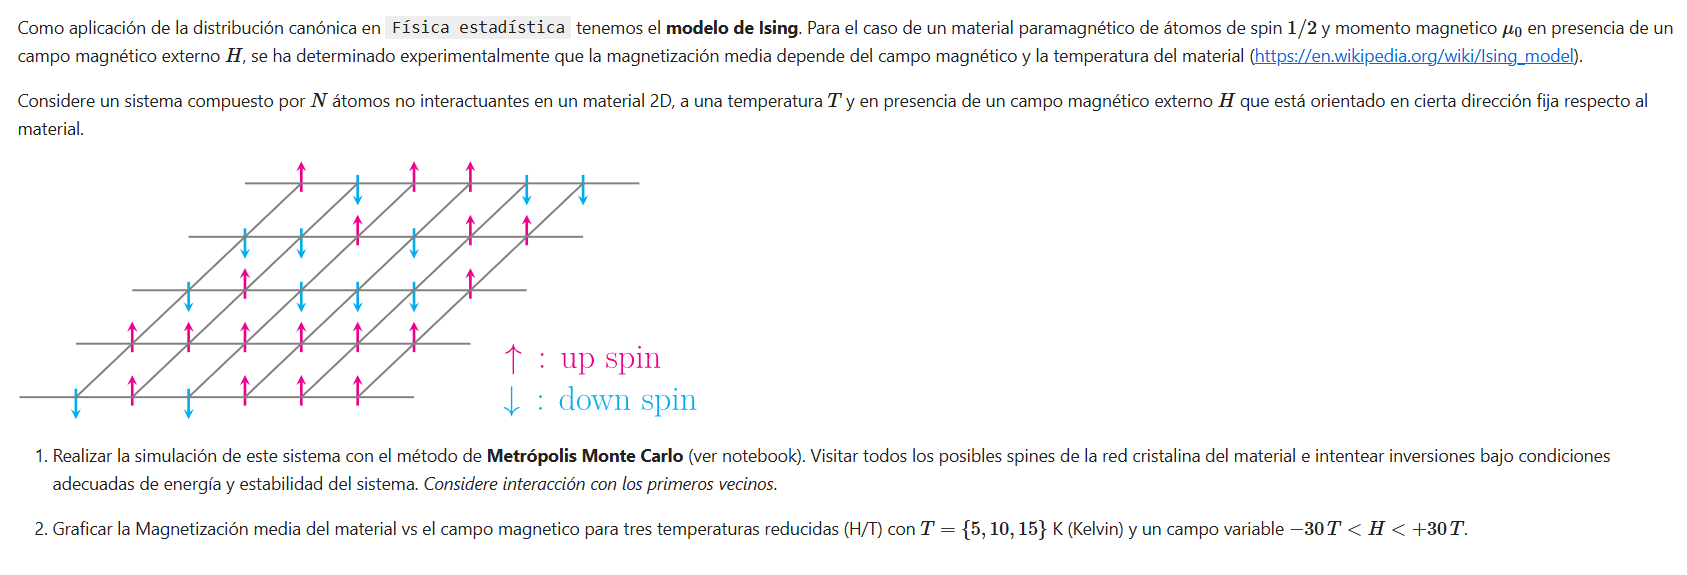

In [7]:
muB = 9.2740100783e-24      # magnetón de Bohr (J/T)
kB  = 1.380649e-23          # constante de Boltzmann (J/K)
C   = muB/kB                # = 0.6717 K/T  (muB*H/kB tiene unidades de K)

print(f"muB/kB = {C:.4f} K/T")


muB/kB = 0.6717 K/T


In [13]:
def Malla(n):
  """
  n = el tamaño de la malla
  """
  malla1 = np.random.choice([-1, 1], size=(n, n)) #crea una matriz n x n con -1 o 1 en cada elemento con igual probabilidad
  return malla1

def SubMalla(n):
  i,j = np.indices((n,n))   #genera matrices nxn con los indices de las filas y las columnas
  miniMalla = [ (i+j) % 2 == 0 , (i+j) % 2 == 1] #sub malla se ve como un tablero de ajedrez
  return miniMalla

def Mc(malla, H, T, J, submalla):
  for i in submalla:
    nn = (np.roll(malla, 1, 0) + np.roll(malla, -1, 0) +
            np.roll(malla, 1, 1) + np.roll(malla, -1, 1))
    # se retorna un matriz con la suma de los 4 vecinos de la matrix original
    """
    [[a,b,c],
      [d,e,f],
      [g,h,i]]

    se consigue

    [[(b+d+c+g) , (a+c+e+h) , (b+f+i+a)],
      [(a+e+g+f) , (b+d+f+h) , (e+c+i+d)],
      [(d+h+a+i) , (g+e+i+b) , (h+f+c+g)]]
    """
    dE = 2 * malla * (J * nn + C * H)

    accept = (dE <= 0) | (np.random.random(malla.shape) < np.exp(-np.clip(dE, 0, None) / T))
    malla[i & accept] *= -1  #i es una matrix de compuesta de true o false, dependiendo de que sibmalla estamos

    #si la energia disminulle dE <= 0 entonces ese cambio es aceptad de una, si no entonces vemos la probabilidad de que se acepte o se rechace

def run(T, J, Hs, n=20, n_therm=200, n_meas=400, red = None):
  # Para cada H: termaliza n_therm barridos y promedia la magnetización
  # por espín m=<sum s>/N durante n_meas barridos. Devuelve m(H) y la red final.
  masks = SubMalla(n)
  if red is None:
    red = Malla(n)
  m_H = []

  for H in Hs:
    for _ in range(n_therm):
        Mc(red, H, T, J, masks) #se estabiliza la mariz aleatoria
    m = 0.0
    for _ in range(n_meas): #se toman  datos
        Mc(red, H, T, J, masks)
        m += red.mean()
    m_H.append(m / n_meas)
  return np.array(m_H), red #devuelve la media de los datos y la red final

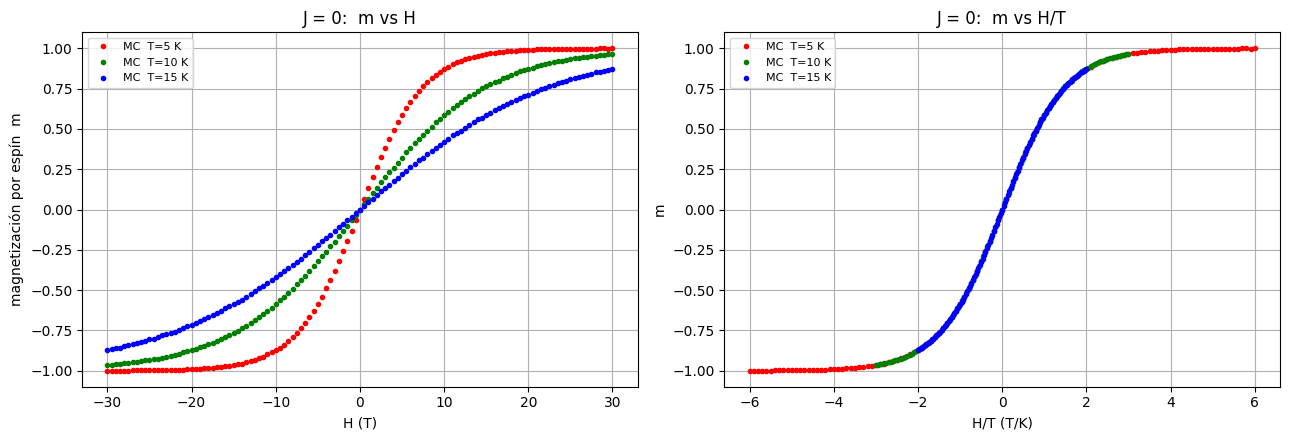

In [9]:
#graficos
Hs = np.arange(-30, 30.01, 0.5)       # campo en Tesla
Ts = [5, 10, 15]                      # temperaturas en K
colors = {5: 'r', 10: 'g', 15: 'b'}

m_J0 = {T: run(T, J=0.0, Hs=Hs)[0] for T in Ts}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for T in Ts:
    ax[0].plot(Hs, m_J0[T], colors[T]+'.', label=f'MC  T={T} K')
    ax[1].plot(Hs/T, m_J0[T], colors[T]+'.', label=f'MC  T={T} K')

ax[0].set(xlabel='H (T)', ylabel='magnetización por espín  m', title='J = 0:  m vs H')
ax[1].set(xlabel='H/T (T/K)', ylabel='m', title='J = 0:  m vs H/T')
for a in ax: a.grid(); a.legend(fontsize=8)
plt.tight_layout(); plt.show()


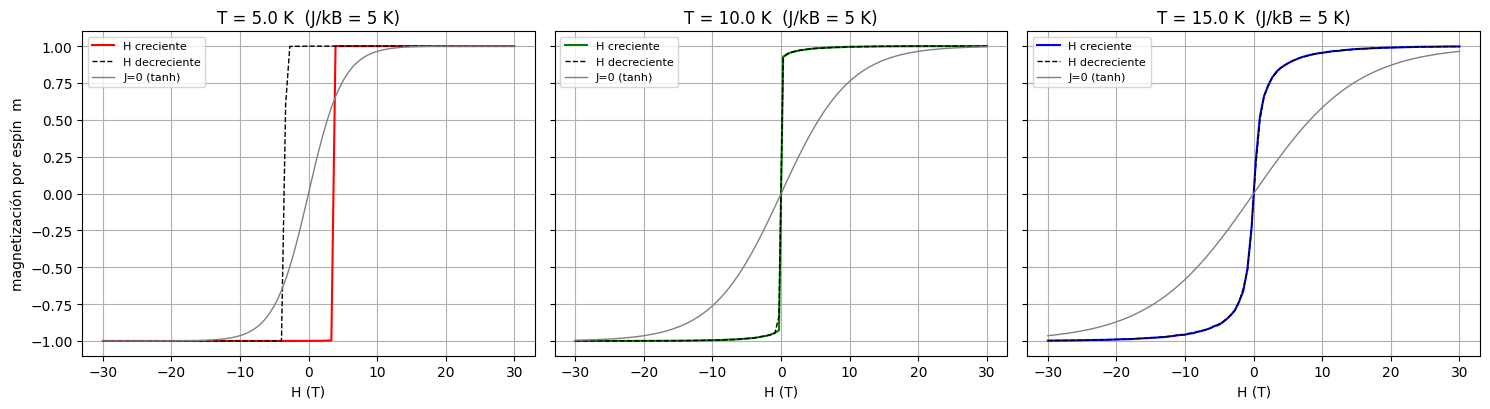

In [19]:
J = 5.0                                # J/kB en kelvin  (parámetro del modelo)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
m_J = {}

for a, T in zip(ax, Ts):
    ida, red   = run(T, J, Hs)                      # H: -30 -> +30
    vuelta, _  = run(T, J, Hs[::-1])                # H: +30 -> -30
    m_J[T] = (ida, vuelta[::-1])
    a.plot(Hs, ida, colors[T], label='H creciente')
    a.plot(Hs, vuelta[::-1],   'k--', lw=1, label='H decreciente')
    a.plot(Hs, np.tanh(C*Hs/T), 'gray', lw=1, label='J=0 (tanh)')
    a.set(xlabel='H (T)', title=f'T = {T} K  (J/kB = {J:g} K)')
    a.grid(); a.legend(fontsize=8)
ax[0].set_ylabel('magnetización por espín  m')
plt.tight_layout(); plt.show()

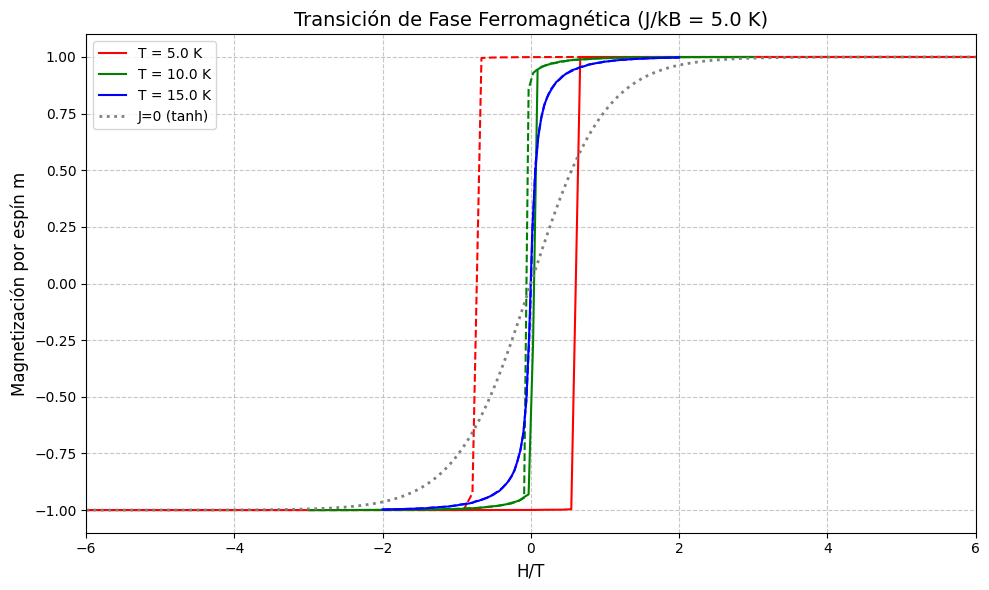

In [18]:
plt.figure(figsize=(10, 6))

for T in Ts:
    ida, red = run(T, J, Hs)
    vuelta, _ = run(T, J, Hs[::-1], red=red)

    # H creciente (línea continua)
    plt.plot(Hs / T, ida, color=colors[T], label=f'T = {T} K')

    # H decreciente (línea punteada, sin label para no saturar la leyenda)
    plt.plot(Hs / T, vuelta[::-1], color=colors[T], linestyle='--', lw=1.5)

x_tanh = np.linspace(-6, 6, 200)
plt.plot(x_tanh, np.tanh(C * x_tanh), color='gray', linestyle=':', lw=2, label='J=0 (tanh)')

plt.xlabel('H/T', fontsize=12)
plt.ylabel('Magnetización por espín m', fontsize=12)
plt.title(f'Transición de Fase Ferromagnética (J/kB = {J} K)', fontsize=14)

plt.xlim(-6, 6)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=10, loc='best')

plt.tight_layout()
plt.show()

la linea puntuada es el ecenario donde pasamos de la red en su estado final en H(30) y se regresa, mostrando como se ve el proceso de histéresis magnetica, cuando no se tiene en cuenta a los vecinos esta propiedad de "memoria" no esta presente